# Nutriva AI — Sprint Review 2: Model
**Tim GarudaCode · Massive Challenge · 27 Oktober 2026**

Notebook ini menjalankan ulang seluruh tahap Model secara end-to-end memakai modul di `src/`:
1. Data → audit label (leakage check) & dataset siap-latih
2. Pemilihan algoritma (5 kandidat + baseline dummy, 5-fold stratified CV)
3. Hyperparameter tuning (RandomizedSearchCV, 40 iterasi, top-2 model)
4. Evaluasi test set (Accuracy, Precision, Recall, F1, Confusion Matrix, ROC-AUC)
5. Simpan & muat ulang model (`joblib`) lalu uji prediksi data baru

Lingkungan: Python 3.13, scikit-learn 1.9.1, xgboost 3.4.1, pandas 3.0.5. Seed = 42.

In [1]:
import sys, json, subprocess
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
import warnings; warnings.filterwarnings('ignore')
import pandas as pd
from IPython.display import Image, display
pd.set_option('display.width', 160)

## 1. Data & audit label
Label `Stunting Risk` dibandingkan dengan kategori WHO Height-for-Age z-score (HAZ) yang dihitung dari tabel LMS WHO 2006.

In [2]:
subprocess.run([sys.executable, str(ROOT/'src/data_prep.py')], check=True, capture_output=True)
print(json.dumps(json.load(open(ROOT/'reports/leakage_check.json')), indent=2, ensure_ascii=False))

{
  "finding": "Label 'Stunting Risk' identik dengan kategori WHO HAZ (TB/U)",
  "rule": {
    "Low": "HAZ >= -2",
    "Medium": "-3 <= HAZ < -2",
    "High": "HAZ < -3"
  },
  "agreement_rate": 1.0,
  "haz_range_per_label": [
    {
      "Stunting Risk": "High",
      "min": -7.816,
      "max": -3.002,
      "count": 420
    },
    {
      "Stunting Risk": "Low",
      "min": -1.999,
      "max": 3.209,
      "count": 1639
    },
    {
      "Stunting Risk": "Medium",
      "min": -3.0,
      "max": -2.002,
      "count": 464
    }
  ],
  "implication": "Model yang memakai Height+Age+Gender hanya mereplikasi rumus WHO. Height & Weight dikeluarkan dari fitur model ML; status aktual dihitung deterministik oleh WHO z-score engine."
}


In [3]:
df = pd.read_csv(ROOT/'data/processed/full_with_zscores.csv')
df.groupby('Stunting Risk')[['HAZ','WAZ','WHZ']].agg(['min','max','mean']).round(2)

HAZ               WAZ               WHZ            
                min   max  mean   min   max  mean   min   max  mean
Stunting Risk                                                      
High          -7.82 -3.00 -4.04 -6.41  0.52 -3.55 -5.26  4.66 -1.28
Low           -2.00  3.21 -0.59 -3.50  2.00 -0.74 -4.21  2.12 -0.59
Medium        -3.00 -2.00 -2.47 -4.40  0.87 -2.30 -4.64  3.51 -1.19

**Temuan:** label 100% identik dengan kategori HAZ (Low ≥ −2; Medium −3 s.d. <−2; High < −3). Maka `Height` dan `Weight` dikeluarkan dari fitur model ML; status aktual dihitung oleh WHO engine.

## 2–4. Training, tuning, evaluasi
`src/train.py` (± 4 menit di 2 vCPU). Hasil tersimpan di `reports/metrics.json`.

In [4]:
# Set RUN_TRAINING = True untuk melatih ulang dari nol
RUN_TRAINING = False
if RUN_TRAINING:
    subprocess.run([sys.executable, str(ROOT/'src/train.py')], check=True)
m = json.load(open(ROOT/'reports/metrics.json'))
rows = [{'model': k, 'macro_f1': f"{v['macro_f1'][0]:.3f} ± {v['macro_f1'][1]:.3f}",
         'balanced_acc': round(v['balanced_acc'][0],3), 'recall_high': round(v['recall_high'][0],3),
         'accuracy': round(v['accuracy'][0],3)} for k,v in m['cv_baseline'].items()]
pd.DataFrame(rows).sort_values('macro_f1', ascending=False)

,model,macro_f1,balanced_acc,recall_high,accuracy
3,Random Forest (balanced),0.581 ± 0.017,0.591,0.598,0.698
2,Logistic Regression (balanced),0.572 ± 0.021,0.598,0.646,0.665
5,XGBoost (sample-weighted),0.552 ± 0.023,0.551,0.518,0.690
1,Logistic Regression,0.547 ± 0.039,0.542,0.524,0.715
4,HistGradientBoosting (balanced),0.545 ± 0.021,0.544,0.506,0.689
0,Dummy (majority),0.263 ± 0.000,0.333,0.000,0.650


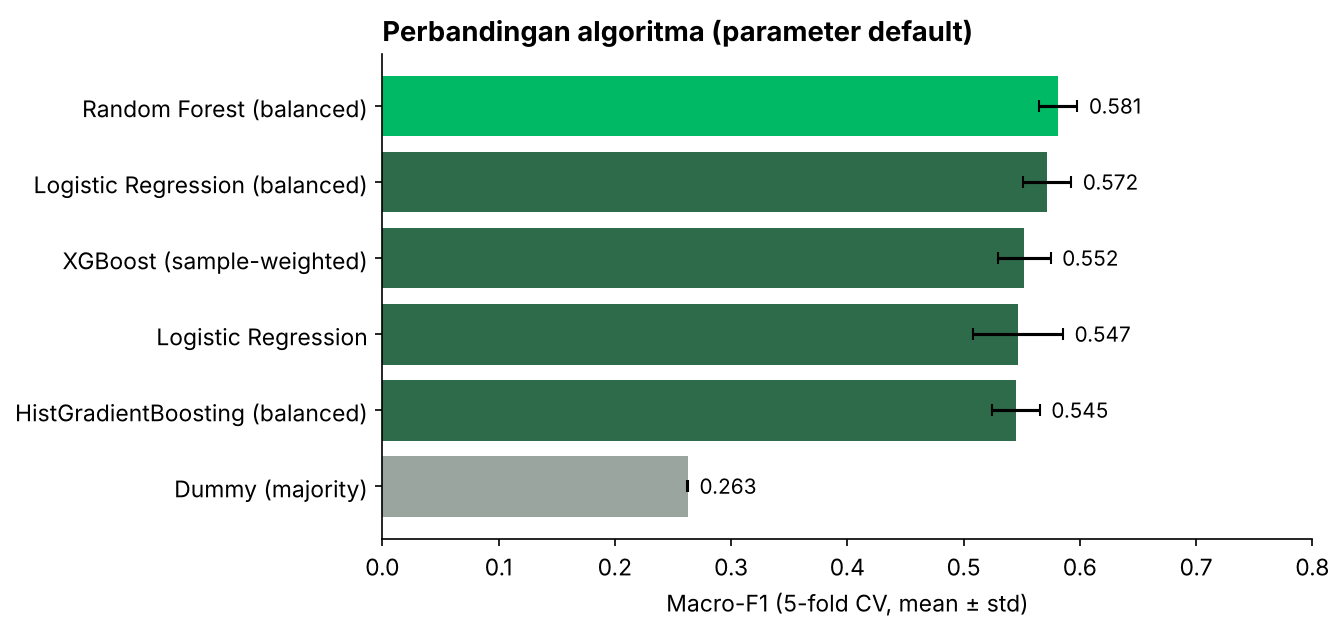

In [5]:
display(Image(ROOT/'reports/figures/01_model_comparison_cv.png'))

In [6]:
for k,v in m['tuning'].items():
    print(k, '| CV macro-F1 =', round(v['cv']['macro_f1'][0],3), '| best params:', v['best_params'])

Random Forest (balanced) | CV macro-F1 = 0.597 | best params: {'class_weight': 'balanced_subsample', 'max_depth': 4, 'max_features': 'log2', 'min_samples_leaf': 4, 'n_estimators': 469}
Logistic Regression (balanced) | CV macro-F1 = 0.592 | best params: {'C': 0.008111941985431923, 'l1_ratio': 0.18340450985343382}


In [7]:
keys = ['accuracy','balanced_accuracy','macro_f1','recall_high','roc_auc_ovr_macro','roc_auc_stunted_vs_normal','macro_f1_bootstrap_95ci']
pd.DataFrame({k: {kk: m['test'][k].get(kk) for kk in keys} for k in m['test']})

,dummy_majority,before_tuning,after_tuning
accuracy,0.6495,0.6614,0.6851
balanced_accuracy,0.3333,0.5704,0.5976
macro_f1,0.2625,0.5568,0.5902
recall_high,0.0000,0.631,0.619
roc_auc_ovr_macro,NaN,0.8026,0.8
roc_auc_stunted_vs_normal,NaN,0.8313,0.8262
macro_f1_bootstrap_95ci,NaN,"[0.511, 0.6036]","[0.5387, 0.6358]"


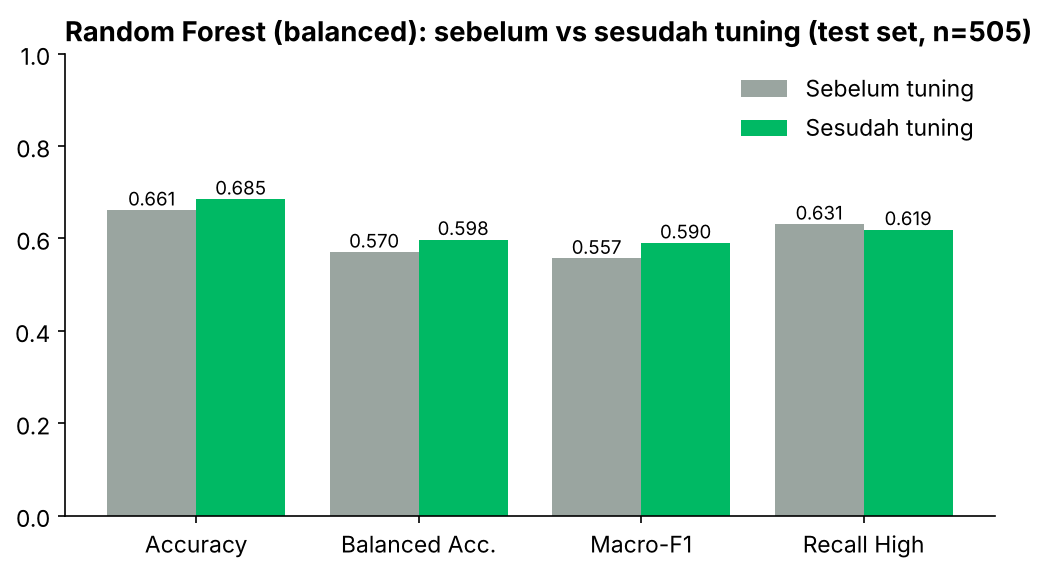

In [8]:
display(Image(ROOT/'reports/figures/02_tuning_before_after.png'))

In [9]:
pc = m['test']['after_tuning']['per_class']
pd.DataFrame({c: pc[c] for c in ['Low','Medium','High','macro avg']}).T.round(3)

,precision,recall,f1-score,support
Low,0.830,0.787,0.808,328.0
Medium,0.346,0.387,0.365,93.0
High,0.578,0.619,0.598,84.0
macro avg,0.585,0.598,0.590,505.0


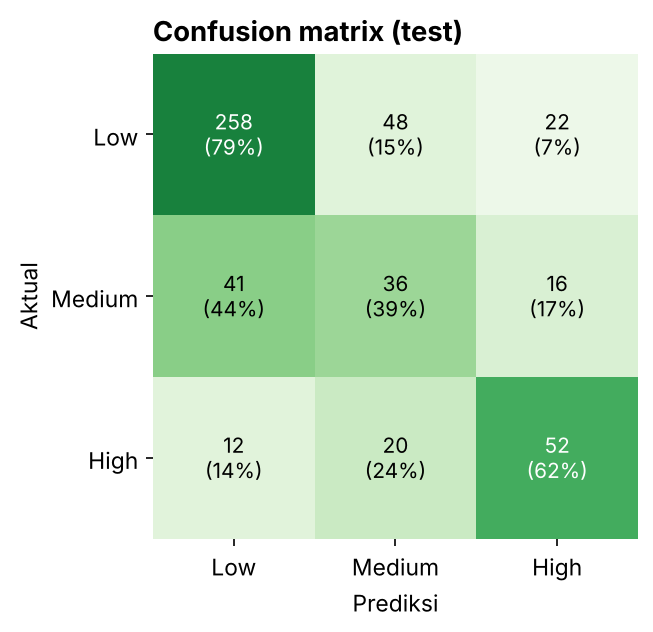

In [10]:
display(Image(ROOT/'reports/figures/03_confusion_matrix.png'))

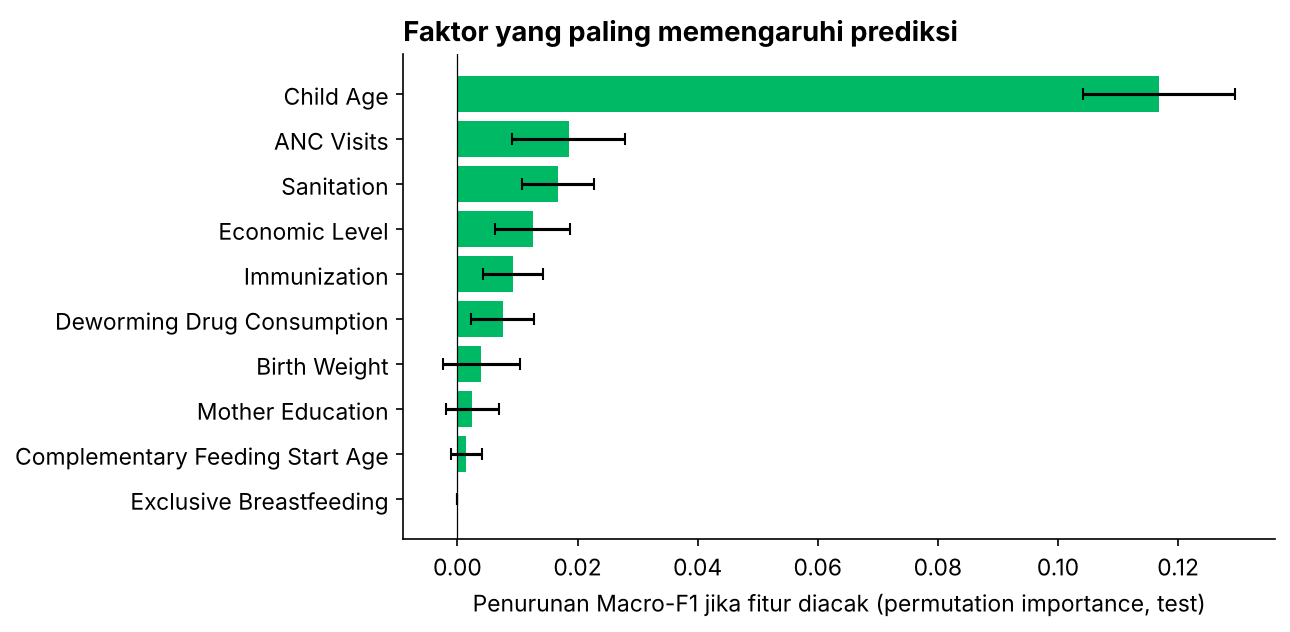

In [11]:
display(Image(ROOT/'reports/figures/04_permutation_importance.png'))

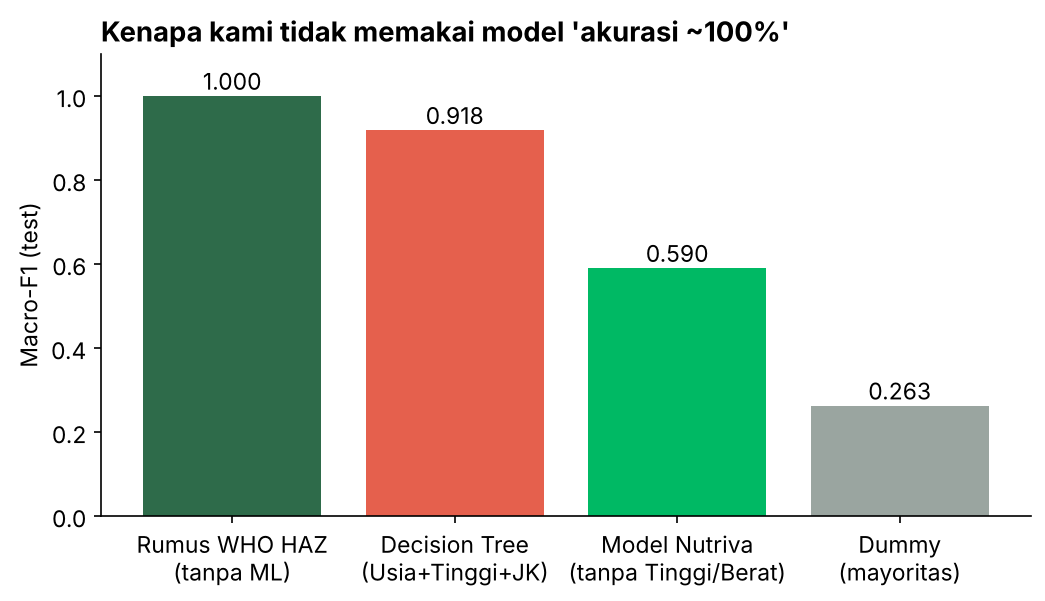

In [12]:
display(Image(ROOT/'reports/figures/05_leakage_demo.png'))

## 5. Load model & prediksi data baru (persona Siti, anak 14 bulan)

In [13]:
import joblib
model = joblib.load(ROOT/'models/nutriva_stunting_risk_v1.joblib')
print(json.load(open(ROOT/'models/model_metadata.json'))['test_metrics'])
from inference import predict
siti = {"child_age_months": 14, "gender": "F", "birth_length_cm": 47.5, "birth_weight_kg": 2.4,
        "mother_age": 24, "mother_education": "High School", "mother_height_cm": 149, "anc_visits": 3,
        "exclusive_breastfeeding": "No", "complementary_feeding_start_months": 5, "immunization": "Incomplete",
        "diarrhea_frequency": 2, "drinking_water_source": "Unprotected", "sanitation": "Improved",
        "economic_level": "Low", "residence_type": "Rural", "deworming": "No", "height_cm": 71.0, "weight_kg": 7.9}
print(json.dumps(predict(siti), indent=2, ensure_ascii=False))

{'accuracy': 0.6851, 'balanced_accuracy': 0.5976, 'macro_f1': 0.5902, 'recall_high': 0.619, 'roc_auc_ovr_macro': 0.8, 'roc_auc_stunted_vs_normal': 0.8262, 'macro_f1_bootstrap_95ci': [0.5387, 0.6358]}


{
  "level": "Medium",
  "basis": "who_measurement",
  "alert": "attention",
  "message": "Perlu perhatian. Disarankan memeriksakan pertumbuhan anak ke Posyandu/Puskesmas dalam waktu dekat dan memperbaiki faktor yang bisa diubah.",
  "growth_status": {
    "haz": {
      "z": -2.01,
      "category": "Pendek (stunted)"
    },
    "waz": {
      "z": -1.43,
      "category": "Berat badan normal"
    },
    "whz": {
      "z": -0.64,
      "category": "Gizi baik (normal)"
    },
    "stunting_level": "Medium",
    "standard": "WHO Child Growth Standards 2006 / Permenkes RI No. 2 Tahun 2020"
  },
  "risk_model": {
    "predicted_level": "High",
    "probabilities": {
      "Low": 0.1903,
      "Medium": 0.3109,
      "High": 0.4988
    },
    "model_version": "1.0.0",
    "algorithm": "Random Forest (balanced)"
  },
  "modifiable_factors": [
    {
      "factor": "Riwayat kunjungan ANC < 4 kali",
      "suggestion": "Diskusikan riwayat kehamilan dengan bidan/Posyandu saat penimbangan beri